# Underwater Vessel Understanding - Review 2

**Goal:** predict the closest vessel's distance (11 one-km bins) and the vessel class (Cargo, Tanker, Fishing, Pilot, Dredging, High-Speed-Craft or Other, within 3 km) from 10-second hydrophone clips.

This notebook has two parts:
1. **Data audit:** check the raw data step by step and build one clean table of clips.
2. **Exploratory data analysis:** look at how the labels are distributed.

Feature extraction and the baseline models (linear SVM, LDA, tree) come next.

We use only the metadata CSV and the audio files. The train / val / test split is read from the folder name of each clip. The `data_split/*.txt` files are not used.

Every audit step runs a check first, and what we do next depends on what the check shows. Generated files (the clean clip table and the figures) are saved in `outputs/`.

## 0. Setup

In [94]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import soundfile as sf
from joblib import Parallel, delayed

pd.set_option("display.max_columns", 50)

### Paths and constants

In [95]:
PROJECT_DIR = Path.cwd()  # the folder containing this notebook

# Raw data (read-only)
DATASET_DIR = PROJECT_DIR / "Dataset"
AUDIO_DIR = DATASET_DIR / "data_per_station_6_paper-window-6_10seconds-efficient_paper_split"
METADATA_CSV = DATASET_DIR / "metadata_database.csv"

# Generated outputs
OUTPUT_DIR = PROJECT_DIR / "outputs"
FIGURE_DIR = OUTPUT_DIR / "figures"
CLIPS_CSV = OUTPUT_DIR / "clips.csv"
AUDIO_INFO_CSV = OUTPUT_DIR / "audio_info.csv"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

SPLITS = ("train", "val", "test")
SAMPLE_RATE = 48_000
CLIP_SECONDS = 10

# Distance task: 11 one-km bins, 0-1 km ... 9-10 km, then 10+ km
N_DISTANCE_BINS = 11
DISTANCE_BIN_LABELS = [f"{i}-{i + 1}" for i in range(N_DISTANCE_BINS - 1)] + ["10+"]

# Vessel-type task: only clips where the labelled vessel is close enough to be audible
NEAR_RANGE_KM = 3.0
MAIN_VESSEL_TYPES = ("Cargo", "Tanker", "Fishing", "Pilot", "Dredging", "High-Speed-Craft")
VESSEL_TYPE_CLASSES = MAIN_VESSEL_TYPES + ("Other",)

RANDOM_STATE = 42

assert METADATA_CSV.exists(), f"Dataset not found at {DATASET_DIR}; open the notebook from the project folder"

### Data helpers

In [96]:
def list_audio_files(audio_dir=AUDIO_DIR):
    """Every WAV path relative to the audio folder, in the same 'folder/file.wav' form as the CSV."""
    return sorted(p.relative_to(audio_dir).as_posix() for p in audio_dir.rglob("*.wav"))


def read_path_parts(file_locations):
    """Station, deployment, split and recording date, read from a clip's path.

    Example path:
    Grafton_15810_train/G_15810_2022-01-20_00-00-18_319-067197_Tanker_underway-using-engine_12-3_3453.wav
    """
    folder = file_locations.str.split("/").str[0]
    file_name = file_locations.str.split("/").str[1]
    folder_parts = folder.str.split("_", expand=True)
    return pd.DataFrame({
        "folder_station": folder_parts[0],
        "deployment": folder_parts[1],
        "split": folder_parts[2],
        "date": pd.to_datetime(file_name.str.extract(r"_(\d{4}-\d{2}-\d{2})_")[0], format="%Y-%m-%d"),
    })


def _audio_info(path):
    info = sf.info(str(path))
    return info.samplerate, info.channels, info.frames


def read_audio_info(file_locations, audio_dir=AUDIO_DIR, n_jobs=16):
    """Sample rate, channels and length of each WAV, read from the file header only (no audio is loaded)."""
    file_locations = list(file_locations)
    rows = Parallel(n_jobs=n_jobs, prefer="threads")(
        delayed(_audio_info)(audio_dir / f) for f in file_locations
    )
    return pd.DataFrame(rows, columns=["samplerate", "channels", "frames"], index=file_locations)


def load_mono(file_location, audio_dir=AUDIO_DIR):
    """Load a clip as one channel of float32 samples between -1 and 1.

    Stereo clips are averaged into one channel. Mono clips are returned as they are.
    """
    audio, rate = sf.read(audio_dir / file_location, dtype="float32", always_2d=True)
    assert rate == SAMPLE_RATE, f"{file_location} has sample rate {rate}"
    return audio.mean(axis=1)

### Plot style
One style for every figure, so the slides look consistent.

In [97]:
SPLIT_COLORS = {"train": "#2a78d6", "val": "#eb6834", "test": "#1baf7a"}
BAR_COLOR = "#2a78d6"
TEXT = "#0b0b0b"
TEXT_MUTED = "#52514e"
GRID = "#e4e3df"

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
    "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "semibold", "axes.titlelocation": "left",
    "axes.edgecolor": GRID, "axes.labelcolor": TEXT_MUTED,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.axisbelow": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "xtick.color": TEXT_MUTED, "ytick.color": TEXT_MUTED, "text.color": TEXT, "legend.frameon": False,
})


def grouped_bars(ax, table, colors):
    """One group per row of `table`, one bar per column, coloured by column name."""
    n = table.shape[1]
    width = 0.8 / n
    x = np.arange(len(table))
    for i, col in enumerate(table.columns):
        ax.bar(x + (i - (n - 1) / 2) * width, table[col], width,
               color=colors[col], edgecolor="white", linewidth=1, label=col)
    ax.set_xticks(x, table.index)
    ax.grid(axis="x", visible=False)
    ax.legend(ncols=n, loc="upper right")


def ranked_barh(ax, series):
    """Horizontal bars sorted largest first, with the value at the end of each bar."""
    series = series.sort_values()
    ax.barh(series.index, series.values, color=BAR_COLOR, height=0.7)
    for y, v in enumerate(series.values):
        ax.text(v, y, f" {v:,}", va="center", fontsize=8, color=TEXT_MUTED)
    ax.grid(axis="y", visible=False)
    ax.margins(x=0.12)

## 1. Data audit

### 1.1 The metadata CSV
`metadata_database.csv` has one row per audio clip. It holds the labels we need:

| Column | Meaning |
|---|---|
| `file_location` | the clip's folder and file name |
| `vessel_type` | type of the closest vessel, for example Tanker |
| `activity` | what the vessel was doing, for example underway-using-engine |
| `SOG` | the vessel's speed over ground, in knots |
| `mmsi` | the vessel's ID (anonymised, for example `ship_001`) |
| `longitude`, `latitude` | the vessel's position |
| `distance` | distance in km between the vessel and the hydrophone |
| `event_time` | when the clip starts (UTC) |
| `station` | the hydrophone station, Grafton or GardenCity |

In [98]:
raw = pd.read_csv(METADATA_CSV)
print(f"Rows in the CSV: {len(raw):,}")
raw.head()

Rows in the CSV: 28,341


,file_location,vessel_type,activity,SOG,mmsi,longitude,latitude,distance,event_time,station
0,Grafton_15810_train/G_15810_2022-01-20_00-00-1...,Tanker,underway-using-engine,12.3,ship_001,2.769215,51.400305,3.453107,2022-01-20 00:05:37.067197+00:00,Grafton
1,Grafton_15810_train/G_15810_2022-01-20_00-10-3...,Tanker,underway-using-engine,12.7,ship_001,2.796890,51.413323,1.781112,2022-01-20 00:11:46.324868+00:00,Grafton
2,Grafton_15810_train/G_15810_2022-01-20_00-10-3...,Tanker,underway-using-engine,12.9,ship_001,2.806048,51.417622,1.679240,2022-01-20 00:13:46.269808+00:00,Grafton
3,Grafton_15810_train/G_15810_2022-01-20_00-10-3...,Tanker,underway-using-engine,13.3,ship_001,2.833360,51.422043,2.189527,2022-01-20 00:18:46.492907+00:00,Grafton
4,Grafton_15810_train/G_15810_2022-01-20_00-20-4...,Tanker,underway-using-engine,13.7,ship_001,2.869545,51.420842,3.970641,2022-01-20 00:24:46.477029+00:00,Grafton


Check each column for missing values.

In [99]:
pd.DataFrame({"missing values": raw.isna().sum(), "type": raw.dtypes.astype(str)})

,missing values,type
file_location,0,str
vessel_type,0,str
activity,108,str
SOG,0,float64
mmsi,0,str
longitude,0,float64
latitude,0,float64
distance,0,float64
event_time,0,str
station,0,str


### 1.2 Clips that have more than one row
A clip should have exactly one row. First count how many clips have extra rows.

In [100]:
print(f"Unique clips: {raw['file_location'].nunique():,}")
print(f"Extra rows (a clip that is already listed above): {raw.duplicated('file_location').sum():,}")

Unique clips: 28,144
Extra rows (a clip that is already listed above): 197


If a clip has two rows, are the two rows identical? If they are, removing one loses nothing. If they differ, we would need to look at them before removing anything. Below are a few clips with extra rows.

In [101]:
dups = raw[raw.duplicated("file_location", keep=False)]
n_conflicting = dups.drop_duplicates().duplicated("file_location").sum()
print(f"Clips whose rows are NOT identical: {n_conflicting:,}")
dups.sort_values("file_location").head(6)

Clips whose rows are NOT identical: 0


,file_location,vessel_type,activity,SOG,mmsi,longitude,latitude,distance,event_time,station
14340,GardenCity_15811_train/G_15811_2022-02-19_00-0...,Tanker,underway-using-engine,8.9,ship_2142,2.204500,51.498145,7.066677,2022-02-19 00:05:15.258640+00:00,GardenCity
14539,GardenCity_15811_train/G_15811_2022-02-19_00-0...,Tanker,underway-using-engine,8.9,ship_2142,2.204500,51.498145,7.066677,2022-02-19 00:05:15.258640+00:00,GardenCity
14540,GardenCity_15811_train/G_15811_2022-02-19_00-0...,Tanker,underway-using-engine,8.7,ship_2142,2.217157,51.506257,6.456456,2022-02-19 00:09:54.656982+00:00,GardenCity
14341,GardenCity_15811_train/G_15811_2022-02-19_00-0...,Tanker,underway-using-engine,8.7,ship_2142,2.217157,51.506257,6.456456,2022-02-19 00:09:54.656982+00:00,GardenCity
14342,GardenCity_15811_train/G_15811_2022-02-19_00-1...,Tanker,underway-using-engine,8.5,ship_2142,2.238810,51.520557,5.938302,2022-02-19 00:17:54.757709+00:00,GardenCity
14541,GardenCity_15811_train/G_15811_2022-02-19_00-1...,Tanker,underway-using-engine,8.5,ship_2142,2.238810,51.520557,5.938302,2022-02-19 00:17:54.757709+00:00,GardenCity


If the count above is 0, every extra row is an exact copy, so we keep one row per clip. If it is not 0, the next cell stops with an error so the difference can be inspected first.

In [102]:
assert n_conflicting == 0, "Some repeated rows are not identical; inspect them before continuing"

meta = (raw.drop_duplicates("file_location")
           .rename(columns={"distance": "distance_km", "SOG": "sog"})
           .reset_index(drop=True))
print(f"Clips after removing extra rows: {len(meta):,}")

Clips after removing extra rows: 28,144


### 1.3 Audio files on disk
Does every clip in the CSV have a WAV file, and does every WAV file have a row in the CSV?

In [103]:
on_disk = set(list_audio_files())
in_csv = set(meta["file_location"])

pd.Series({
    "Clips in the CSV": len(in_csv),
    "WAV files on disk": len(on_disk),
    "In the CSV but no WAV file on disk": len(in_csv - on_disk),
    "WAV file on disk but not in the CSV": len(on_disk - in_csv),
}, name="clips").to_frame()

,clips
Clips in the CSV,28144
WAV files on disk,27564
In the CSV but no WAV file on disk,580
WAV file on disk but not in the CSV,0


A clip without a WAV file cannot be used, so those rows are dropped.

In [104]:
clips = meta[meta["file_location"].isin(on_disk)].reset_index(drop=True)
print(f"Clips kept: {len(clips):,}")

Clips kept: 27,564


### 1.4 Extra information hidden in the clip path
The CSV has no column for the split, the recorder deployment or the recording date. But every clip's path contains them. Take this path:

`Grafton_15810_train/G_15810_2022-01-20_00-00-18_319-067197_Tanker_underway-using-engine_12-3_3453.wav`

The part before the `/` is the folder name, and the part after it is the file name. We read four things out of it and add them to the table as new columns:

| New column | Where it comes from | In the example |
|---|---|---|
| `folder_station` | first word of the folder name | Grafton |
| `deployment` | number in the folder name (the recorder is put in the sea, collected, and put out again under a new number) | 15810 |
| `split` | last word of the folder name | train |
| `date` | date in the file name | 2022-01-20 |

This only works if every path has the same layout, so first check that every folder name has exactly three words (station, deployment, split) and that a date can be found in every file name.

In [105]:
folder_words = clips["file_location"].str.split("/").str[0].str.split("_").str.len()
print("Words in the folder name:")
print(folder_words.value_counts().to_string())

parts = read_path_parts(clips["file_location"])
print()
print("Missing values after reading the path:")
print(parts.isna().sum().to_string())

Words in the folder name:
file_location
3    27564

Missing values after reading the path:
folder_station    0
deployment        0
split             0
date              0


In [106]:
clips = clips.join(parts)
clips.head()

,file_location,vessel_type,activity,sog,mmsi,longitude,latitude,distance_km,event_time,station,folder_station,deployment,split,date
0,Grafton_15810_train/G_15810_2022-01-20_00-00-1...,Tanker,underway-using-engine,12.3,ship_001,2.769215,51.400305,3.453107,2022-01-20 00:05:37.067197+00:00,Grafton,Grafton,15810,train,2022-01-20
1,Grafton_15810_train/G_15810_2022-01-20_00-10-3...,Tanker,underway-using-engine,12.7,ship_001,2.796890,51.413323,1.781112,2022-01-20 00:11:46.324868+00:00,Grafton,Grafton,15810,train,2022-01-20
2,Grafton_15810_train/G_15810_2022-01-20_00-10-3...,Tanker,underway-using-engine,12.9,ship_001,2.806048,51.417622,1.679240,2022-01-20 00:13:46.269808+00:00,Grafton,Grafton,15810,train,2022-01-20
3,Grafton_15810_train/G_15810_2022-01-20_00-10-3...,Tanker,underway-using-engine,13.3,ship_001,2.833360,51.422043,2.189527,2022-01-20 00:18:46.492907+00:00,Grafton,Grafton,15810,train,2022-01-20
4,Grafton_15810_train/G_15810_2022-01-20_00-20-4...,Tanker,underway-using-engine,13.7,ship_001,2.869545,51.420842,3.970641,2022-01-20 00:24:46.477029+00:00,Grafton,Grafton,15810,train,2022-01-20


The CSV already has a `station` column, so we now have the station twice: once from the CSV and once from the folder name. If the path was read correctly, both should always agree. Count the clips where they don't.

In [107]:
print(f"Clips where the CSV station differs from the folder station: {(clips['station'] != clips['folder_station']).sum():,}")

Clips where the CSV station differs from the folder station: 0


### 1.5 Train / validation / test split
The dataset's README describes the split like this:
- The split is by **recording day**: all clips from one station on one day go into a single set (train, validation or test).
- This avoids near-identical audio (same weather, noise, ships) in both train and test.
- The proportions are about 79.4% train, 10.6% validation and 9.9% test.
- The README does not say how days were assigned to sets. Section 1.9 checks the day-level claim on the data.
- The split does **not** separate ships: the same ship can appear in train and test.

The set of each clip is the last word of its folder name. Check which values appear and how many clips each has.

In [108]:
print("Values found in the folder names:", sorted(clips["split"].unique()))
assert set(clips["split"]) <= set(SPLITS), "Unexpected split name in a folder"

clips["split"] = pd.Categorical(clips["split"], categories=SPLITS)
split_sizes = clips["split"].value_counts().reindex(SPLITS)
pd.DataFrame({"clips": split_sizes, "share": (split_sizes / len(clips)).map("{:.1%}".format)})

Values found in the folder names: ['test', 'train', 'val']


,clips,share
split,,
train,21882,79.4%
val,2934,10.6%
test,2748,10.0%


### 1.6 Do the file names agree with the CSV?
Each file name also contains the vessel type and the distance in metres (the last number). That is a second copy of two labels we already have in the CSV. Check that the file names have the layout we expect, then compare.

`..._Tanker_underway-using-engine_12-3_3453.wav` means vessel type Tanker, speed 12.3 knots, distance 3,453 m.

In [109]:
tokens = clips["file_location"].str.split("/").str[1].str.removesuffix(".wav").str.split("_")
print("Parts in each file name:")
print(tokens.str.len().value_counts().to_string())
assert (tokens.str.len() == 9).all(), "Some file names have a different layout"

Parts in each file name:
file_location
9    27564


Now compare the two copies of each label, for every clip:
- **Distance:** the CSV gives it in km (for example `3.453107`) and the file name gives it in metres (`3453`). We divide the file-name value by 1000 and compare. A difference of up to 10 m is just rounding, so only larger differences count.
- **Vessel type:** the CSV column against the type written in the file name.

For the distance we also check something stricter. The distance task uses 1-km bins, so a small difference only matters if it pushes the clip into a different bin. For example, 4.49 km is in bin 4-5, while 3.758 km is in bin 3-4, so the label would change.

In [110]:
name_distance_km = tokens.str[8].astype(int) / 1000
name_vessel_type = tokens.str[5]

csv_bin = np.minimum(np.floor(clips["distance_km"]), N_DISTANCE_BINS - 1)
name_bin = np.minimum(np.floor(name_distance_km), N_DISTANCE_BINS - 1)

print(f"Distance differs by more than 10 m: {((name_distance_km - clips['distance_km']).abs() > 0.01).sum():,}")
print(f"Distance falls in a different 1-km bin: {(csv_bin != name_bin).sum():,}")
print(f"Vessel type differs: {(name_vessel_type != clips['vessel_type']).sum():,}")
print(f"Out of {len(clips):,} clips")

Distance differs by more than 10 m: 1,881
Distance falls in a different 1-km bin: 1,115
Vessel type differs: 0
Out of 27,564 clips


**What the numbers above mean:**
- The vessel type is always the same in both places.
- The distance is not. For 1,881 clips it differs by more than 10 m, and for 1,115 of them the difference is large enough to move the clip into a different 1-km bin. So the distance label depends on which copy we trust. For example, the clip `G_15810_2022-01-28_00-10-35_29-195111_..._4490.wav` has distance 5.979 km in the CSV, but its file name says 4,490 m.

The data alone cannot tell us which copy is right. **Decision:** we use the **CSV** for all labels (distance, vessel type, activity, speed and ship ID), because it is the dataset's documented metadata table and keeps every label in one place. We will mention this disagreement as a limitation.

### 1.7 Audio format
The README says every clip is 48 kHz, mono and 10 seconds long. Check this on every WAV file (only the file header is read, not the audio). The result is saved in `outputs/audio_info.csv`.

In [111]:
if AUDIO_INFO_CSV.exists():
    info = pd.read_csv(AUDIO_INFO_CSV, index_col=0)
else:
    info = read_audio_info(clips["file_location"])
    info.to_csv(AUDIO_INFO_CSV)

expected_frames = SAMPLE_RATE * CLIP_SECONDS
bad = info[(info["samplerate"] != SAMPLE_RATE)
           | (info["channels"] != 1)
           | (info["frames"] != expected_frames)]
print(f"Clips that are not 48 kHz / mono / 10 s: {len(bad):,}")
info.value_counts().rename("clips").to_frame()

Clips that are not 48 kHz / mono / 10 s: 14,684


clips
samplerate channels frames       
48000      2        480000  14023
           1        480000  12880
           2        0           8
           1        111204      2
                    0           2
...                           ...
                    156543      1
                    397698      1
                    154876      1
                    187441      1
                    131032      1

[650 rows x 1 columns]

The table above shows that many clips are not what the README describes:
- About half of the clips are **stereo** (2 channels) instead of mono. The model needs one signal per clip, so when we extract features we will average the two channels into one. Here we only mark which clips are stereo.
- Some clips are **shorter than 10 seconds**, and a few are empty. A very short clip gives unreliable features, and its label was worked out for a full 10-second window. So we drop every clip shorter than 5 seconds (`MIN_CLIP_SECONDS`) and keep the rest. The features we plan to use (the mean, spread, minimum and maximum of the MFCCs) do not depend on the clip length, so the clips between 5 and 10 seconds need no padding.

First add the audio details to the clip table and count the clips in each group.

In [112]:
MIN_CLIP_SECONDS = 5  # clips shorter than this are dropped

clips = clips.drop(columns=info.columns, errors="ignore").join(info, on="file_location")
clips["seconds"] = clips["frames"] / SAMPLE_RATE
clips["is_stereo"] = clips["channels"] == 2
clips["too_short"] = clips["seconds"] < MIN_CLIP_SECONDS

full_length = clips["frames"] == expected_frames
print(f"Stereo clips: {clips['is_stereo'].sum():,} of {len(clips):,}")
print(f"Clips of exactly 10 s: {full_length.sum():,}")
print(f"Clips between {MIN_CLIP_SECONDS} s and 10 s (or slightly over), kept as they are: "
      f"{(~full_length & ~clips['too_short']).sum():,}")
print(f"Clips shorter than {MIN_CLIP_SECONDS} s, including empty files (to drop): {clips['too_short'].sum():,}")

Stereo clips: 14,489 of 27,564
Clips of exactly 10 s: 26,903
Clips between 5 s and 10 s (or slightly over), kept as they are: 304
Clips shorter than 5 s, including empty files (to drop): 357


Now drop the clips shorter than 5 seconds. Every later section works with the clips that remain.

In [113]:
n_before = len(clips)
clips = clips[~clips["too_short"]].reset_index(drop=True)
print(f"Dropped {n_before - len(clips):,} clips; {len(clips):,} clips remain")
print()
print("Clips per split after dropping:")
print(clips["split"].value_counts().reindex(SPLITS).to_string())

Dropped 357 clips; 27,207 clips remain

Clips per split after dropping:
split
train    21604
val       2892
test      2711


**Converting stereo clips to mono**

The models need one signal per clip, but about half of the clips have two channels (left and right). We turn a stereo clip into mono by taking the average of the left and right value at every moment. 

We do not save new mono files. Together they would take about 26 GB of disk space. Instead, the function `load_mono` (defined with the other helpers at the top) does the conversion each time a clip is loaded. It also converts the 16-bit integer samples into numbers between -1 and 1.

In [114]:
full_length = clips["frames"] == expected_frames
stereo_example = clips.loc[clips["is_stereo"] & full_length, "file_location"].iloc[0]
mono_example = clips.loc[~clips["is_stereo"] & full_length, "file_location"].iloc[0]

stereo_raw, _ = sf.read(AUDIO_DIR / stereo_example, dtype="float32")  # shape: (samples, channels)
stereo_as_mono = load_mono(stereo_example)
mono_loaded = load_mono(mono_example)

print(f"Stereo clip as stored in the file: {stereo_raw.shape}  (samples, channels)")
print(f"Stereo clip after load_mono:       {stereo_as_mono.shape}")
print(f"Mono clip after load_mono:         {mono_loaded.shape}")
print(f"load_mono equals the average of left and right: {np.allclose(stereo_raw.mean(axis=1), stereo_as_mono)}")

pd.DataFrame({"left": stereo_raw[:5, 0], "right": stereo_raw[:5, 1],
              "mono (average of left and right)": stereo_as_mono[:5]})

Stereo clip as stored in the file: (480000, 2)  (samples, channels)
Stereo clip after load_mono:       (480000,)
Mono clip after load_mono:         (480000,)
load_mono equals the average of left and right: True


,left,right,mono (average of left and right)
0,-0.002747,-0.002014,-0.002380
1,-0.002350,-0.001648,-0.001999
2,-0.002502,-0.001556,-0.002029
3,-0.002625,-0.001923,-0.002274
4,-0.002136,-0.002106,-0.002121


### 1.8 Task labels
Two labels are made from the CSV columns:
- `dist_bin`: the distance task label. 0 means 0-1 km, 1 means 1-2 km, and so on up to 10, which means 10 km or more.
- `vessel_class`: the vessel-type task label, made by grouping the vessel types in the CSV.

The vessel-type task uses only the clips with the vessel within 3 km (`near_range`), because farther vessels are probably too quiet to hear.

Before grouping any vessel types, look at how many clips each type has.

In [130]:
type_table = clips["vessel_type"].value_counts().to_frame("clips")
type_table.loc["Total"] = type_table["clips"].sum()
type_table.index.name = "vessel type"
type_table

,clips
vessel type,
Cargo,12721
Tanker,6737
Fishing,2128
Pilot,1416
Other,1302
Dredging,1268
High-Speed-Craft,624
Passenger,315
Tug,284


- Cargo and Tanker have by far the most clips.
- Fishing, Other, Dredging, High-Speed-Craft and Pilot come next, with about 600 to 2,100 clips each.
- The remaining 12 types have at most 315 clips each, which is too few to learn from or to test on.

**Decision:** keep Cargo, Tanker, Fishing, Pilot, Dredging and High-Speed-Craft as separate classes, and group all the other types into **Other**.

**Check before training:** the vessel-type task uses only clips within 3 km. Section 2.6 shows how many clips each class has there, in each split. Every class needs clips in val and test, otherwise it cannot be measured.

Now create the labels.

In [115]:
clips["dist_bin"] = np.minimum(np.floor(clips["distance_km"]), N_DISTANCE_BINS - 1).astype(int)
clips["vessel_class"] = clips["vessel_type"].where(clips["vessel_type"].isin(MAIN_VESSEL_TYPES), "Other")
clips["near_range"] = clips["distance_km"] <= NEAR_RANGE_KM

clips[["file_location", "split", "station", "date", "distance_km", "dist_bin",
       "vessel_type", "vessel_class", "near_range", "mmsi"]].head()

,file_location,split,station,date,distance_km,dist_bin,vessel_type,vessel_class,near_range,mmsi
0,Grafton_15810_train/G_15810_2022-01-20_00-00-1...,train,Grafton,2022-01-20,3.453107,3,Tanker,Tanker,False,ship_001
1,Grafton_15810_train/G_15810_2022-01-20_00-10-3...,train,Grafton,2022-01-20,1.781112,1,Tanker,Tanker,True,ship_001
2,Grafton_15810_train/G_15810_2022-01-20_00-10-3...,train,Grafton,2022-01-20,1.679240,1,Tanker,Tanker,True,ship_001
3,Grafton_15810_train/G_15810_2022-01-20_00-10-3...,train,Grafton,2022-01-20,2.189527,2,Tanker,Tanker,True,ship_001
4,Grafton_15810_train/G_15810_2022-01-20_00-20-4...,train,Grafton,2022-01-20,3.970641,3,Tanker,Tanker,False,ship_001


How many clips does each label have now? The vessel classes are counted for all clips and for the clips within 3 km, which are the ones the vessel-type task uses.

In [116]:
dist_counts = clips["dist_bin"].value_counts().reindex(range(N_DISTANCE_BINS), fill_value=0)
dist_counts.index = DISTANCE_BIN_LABELS
dist_table = pd.DataFrame({"clips": dist_counts, "share": (dist_counts / dist_counts.sum()).map("{:.1%}".format)})
dist_table.index.name = "distance bin (km)"

class_table = pd.DataFrame({
    "all clips": clips["vessel_class"].value_counts(),
    "within 3 km": clips.loc[clips["near_range"], "vessel_class"].value_counts(),
}).reindex(VESSEL_TYPE_CLASSES, fill_value=0)
class_table.index.name = "vessel class"

display(dist_table)
display(class_table)

,clips,share
distance bin (km),,
0-1,644,2.4%
1-2,2911,10.7%
2-3,3729,13.7%
3-4,5046,18.5%
4-5,5826,21.4%
5-6,4082,15.0%
6-7,2197,8.1%
7-8,1048,3.9%
8-9,492,1.8%


,all clips,within 3 km
vessel class,,
Cargo,12721,3558
Tanker,6737,1073
Fishing,2128,958
Pilot,1416,23
Dredging,1268,502
High-Speed-Craft,624,350
Other,2313,820


### 1.9 Leakage checks
Leakage means information from the test set reaching the training set, which makes the test score look better than it is.

First check the README's claim: no station-day should have clips in more than one set.

In [117]:
day_splits = clips.groupby(["station", "date"])["split"].nunique()
print(f"Station-days with clips in more than one set: {(day_splits > 1).sum()}")

date_splits = clips.groupby("date")["split"].nunique()
print(f"Dates with clips in more than one set (this can happen across the two stations): {(date_splits > 1).sum()}")

Station-days with clips in more than one set: 0
Dates with clips in more than one set (this can happen across the two stations): 10


The split is by day, not by ship. Check how many ships appear in both train and test.

In [118]:
train_ships = set(clips.loc[clips["split"] == "train", "mmsi"])
clips["ship_seen_in_train"] = clips["mmsi"].isin(train_ships)

test = clips[clips["split"] == "test"]
print(f"Test ships that also appear in train: {test.loc[test['ship_seen_in_train'], 'mmsi'].nunique():,} "
      f"of {test['mmsi'].nunique():,}")
print(f"Test clips from those ships: {test['ship_seen_in_train'].sum():,} of {len(test):,}")

Test ships that also appear in train: 316 of 589
Test clips from those ships: 1,636 of 2,711


## 2. Exploratory data analysis

### 2.1 Clips per split and station

In [119]:
split_table = pd.crosstab(clips["split"], clips["station"], margins=True, margins_name="Total")
split_table["Share"] = (split_table["Total"] / len(clips)).map("{:.1%}".format)
split_table

station,GardenCity,Grafton,Total,Share
split,,,,
train,8903,12701,21604,79.4%
val,1379,1513,2892,10.6%
test,1179,1532,2711,10.0%
Total,11461,15746,27207,100.0%


### 2.2 Deployments

In [128]:
deployments = (clips.groupby(["station", "deployment"])
               .agg(first_day=("date", "min"), last_day=("date", "max"),
                    days=("date", "nunique"), clips=("file_location", "size")))

total = pd.DataFrame(
    {"first_day": deployments["first_day"].min(), "last_day": deployments["last_day"].max(),
     "days": deployments["days"].sum(), "clips": deployments["clips"].sum()},
    index=pd.MultiIndex.from_tuples([("Total", "")], names=deployments.index.names))

pd.concat([deployments, total])

first_day   last_day  days  clips
station    deployment                                   
GardenCity 15811      2022-01-20 2022-05-20    51  11006
           26981      2022-06-24 2022-06-26     2    455
Grafton    15810      2022-01-20 2022-05-08    50  11182
           28434      2022-08-20 2022-09-15    14   3231
           29187      2022-10-28 2022-11-05     5   1333
Total                 2022-01-20 2022-11-05   122  27207

### 2.3 Distance

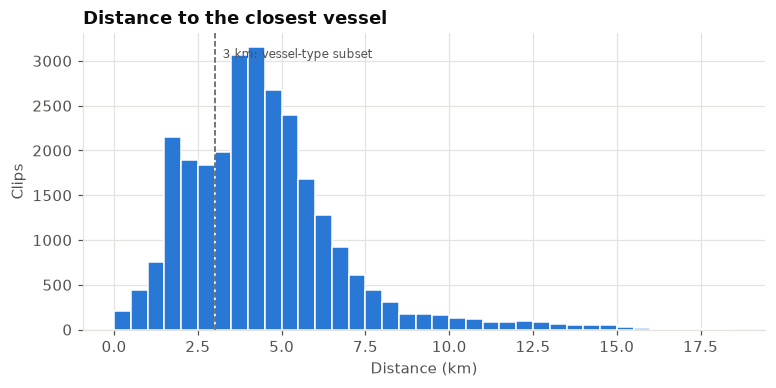

,count,mean,std,min,25%,50%,75%,max
distance (km),27207.0,4.45074,2.342613,0.04619,2.865793,4.190104,5.466848,18.429037


In [121]:
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(clips["distance_km"], bins=np.arange(0, clips["distance_km"].max() + 0.5, 0.5),
        color=BAR_COLOR, edgecolor="white", linewidth=1)
ax.axvline(NEAR_RANGE_KM, color=TEXT_MUTED, linestyle="--", linewidth=1)
ax.text(NEAR_RANGE_KM, ax.get_ylim()[1] * 0.95, "  3 km: vessel-type subset",
        color=TEXT_MUTED, fontsize=8, va="top")
ax.set(title="Distance to the closest vessel", xlabel="Distance (km)", ylabel="Clips")
fig.savefig(FIGURE_DIR / "distance_hist.png")
plt.show()

clips["distance_km"].describe().to_frame("distance (km)").T

### 2.4 Distance bins per split
Shown as a share of each split, so the three splits can be compared directly.

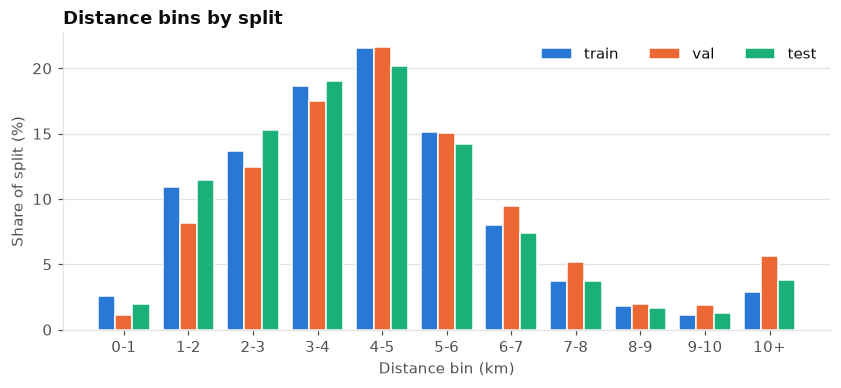

split,train,val,test,total
0-1,558,33,53,644
1-2,2364,237,310,2911
2-3,2954,360,415,3729
3-4,4024,506,516,5046
4-5,4654,625,547,5826
5-6,3262,435,385,4082
6-7,1723,273,201,2197
7-8,797,150,101,1048
8-9,392,56,44,492
9-10,247,55,35,337


In [122]:
bin_counts = pd.crosstab(clips["dist_bin"], clips["split"]).reindex(range(N_DISTANCE_BINS), fill_value=0)
bin_counts.index = DISTANCE_BIN_LABELS
bin_share = bin_counts / bin_counts.sum() * 100

fig, ax = plt.subplots(figsize=(9, 3.5))
grouped_bars(ax, bin_share, SPLIT_COLORS)
ax.set(title="Distance bins by split", xlabel="Distance bin (km)", ylabel="Share of split (%)")
fig.savefig(FIGURE_DIR / "distance_bins_by_split.png")
plt.show()

bin_counts.assign(total=bin_counts.sum(axis=1))

### 2.5 Vessel types

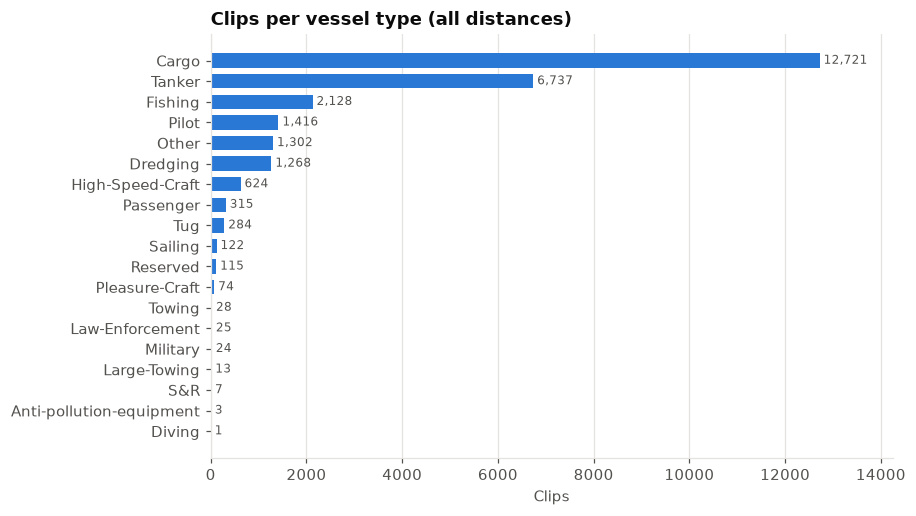

,clips,ships
vessel_type,,
Cargo,12721,2144
Tanker,6737,1203
Fishing,2128,118
Pilot,1416,37
Other,1302,126
Dredging,1268,58
High-Speed-Craft,624,49
Passenger,315,47
Tug,284,37


In [123]:
type_counts = clips["vessel_type"].value_counts()

fig, ax = plt.subplots(figsize=(8, 5))
ranked_barh(ax, type_counts)
ax.set(title="Clips per vessel type (all distances)", xlabel="Clips")
fig.savefig(FIGURE_DIR / "vessel_types.png")
plt.show()

pd.DataFrame({"clips": type_counts,
              "ships": clips.groupby("vessel_type")["mmsi"].nunique()}).sort_values("clips", ascending=False)

### 2.6 Vessel-type task subset (within 3 km)

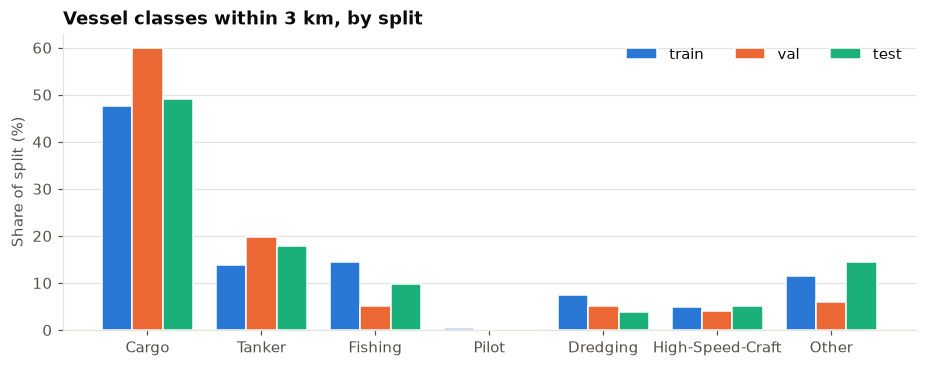

Clips within 3 km: 7,284 of 27,207


split,train,val,test,total
vessel_class,,,,
Cargo,2798,378,382,3558
Tanker,809,125,139,1073
Fishing,850,32,76,958
Pilot,23,0,0,23
Dredging,441,32,29,502
High-Speed-Craft,284,26,40,350
Other,671,37,112,820


In [124]:
near = clips[clips["near_range"]]
class_counts = pd.crosstab(near["vessel_class"], near["split"]).reindex(VESSEL_TYPE_CLASSES, fill_value=0)
class_share = class_counts / class_counts.sum() * 100

fig, ax = plt.subplots(figsize=(10, 3.5))
grouped_bars(ax, class_share, SPLIT_COLORS)
ax.set(title="Vessel classes within 3 km, by split", ylabel="Share of split (%)")
fig.savefig(FIGURE_DIR / "vessel_class_by_split.png")
plt.show()

print(f"Clips within 3 km: {len(near):,} of {len(clips):,}")
class_counts.assign(total=class_counts.sum(axis=1))

### 2.7 Clips per ship

In [ ]:
per_ship = clips["mmsi"].value_counts()

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(per_ship, bins=np.logspace(0, np.log10(per_ship.max()), 30),
        color=BAR_COLOR, edgecolor="white", linewidth=1)
ax.set_xscale("log")
ax.set(title="Clips per ship", xlabel="Clips per ship (log scale)", ylabel="Ships")
fig.savefig(FIGURE_DIR / "clips_per_ship.png")
plt.show()

per_ship.describe().to_frame("clips per ship").T

### 2.8 Speed and activity

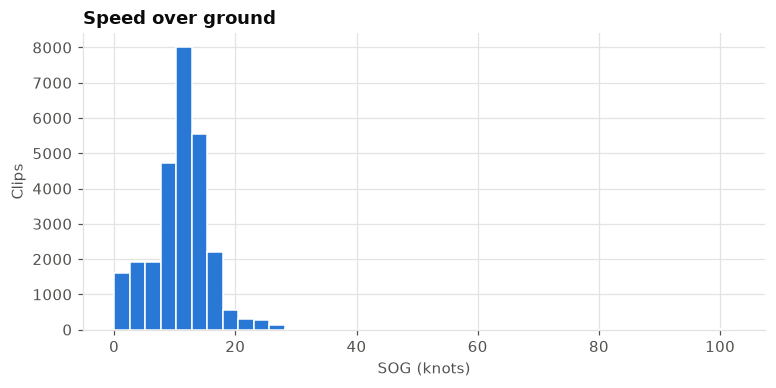

,clips
activity,
underway-using-engine,23454
engaged-in-fishing,1178
restricted-maneuverability,1037
moored,381
constrained-by-her-draught,292
undefined-=-default,250
underway-sailing,247
at-anchor,226
power-driven-vessel-towing-astern,39


In [126]:
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(clips["sog"], bins=40, color=BAR_COLOR, edgecolor="white", linewidth=1)
ax.set(title="Speed over ground", xlabel="SOG (knots)", ylabel="Clips")
fig.savefig(FIGURE_DIR / "sog_hist.png")
plt.show()

clips["activity"].value_counts().to_frame("clips")

## 3. Save the clean clip table
Two files are saved in `outputs/`:
- `audio_info.csv` (saved in 1.7): the sample rate, number of channels and length of every WAV file, read from the file headers. Reading 27,564 headers takes a minute or two, so the result is saved and reused on later runs.
- `clips.csv` (saved below): the final clean table, with one row per clip. Every later step, feature extraction and training, reads this file instead of the raw files.

The audit and EDA tables above have many columns that training does not need, such as speed, position and the audio header details. `clips.csv` keeps only these:

| Column | Used for |
|---|---|
| `file_location` | loading the audio of the clip |
| `split` | train, val or test |
| `distance_km` | the exact distance, and the 3 km limit |
| `dist_bin` | the distance task label |
| `vessel_class` | the vessel-type task label |
| `near_range` | selecting the clips within 3 km for the vessel-type task |
| `station` | testing how well a model transfers from one station to the other |
| `mmsi` | the ship ID, for checks by ship and for the ship-embedding extension |

In [134]:
FINAL_COLUMNS = ["file_location", "split", "station", "mmsi",
                 "distance_km", "dist_bin", "vessel_class", "near_range"]

final = clips[FINAL_COLUMNS]
final.to_csv(CLIPS_CSV, index=False)
print(f"Saved {len(final):,} clips to {CLIPS_CSV}")

Saved 27,207 clips to e:\MLOE Project\outputs\clips.csv


This is the final table, as it will be used for feature extraction and training:

In [135]:
print(f"{final.shape[0]:,} clips, {final.shape[1]} columns")
final

27,207 clips, 8 columns


,file_location,split,station,mmsi,distance_km,dist_bin,vessel_class,near_range
0,Grafton_15810_train/G_15810_2022-01-20_00-00-1...,train,Grafton,ship_001,3.453107,3,Tanker,False
1,Grafton_15810_train/G_15810_2022-01-20_00-10-3...,train,Grafton,ship_001,1.781112,1,Tanker,True
2,Grafton_15810_train/G_15810_2022-01-20_00-10-3...,train,Grafton,ship_001,1.679240,1,Tanker,True
3,Grafton_15810_train/G_15810_2022-01-20_00-10-3...,train,Grafton,ship_001,2.189527,2,Tanker,True
4,Grafton_15810_train/G_15810_2022-01-20_00-20-4...,train,Grafton,ship_001,3.970641,3,Tanker,False
...,...,...,...,...,...,...,...,...
27202,Grafton_29187_train/G_29187_2022-11-05_23-31-4...,train,Grafton,ship_3589,4.905395,4,Cargo,False
27203,Grafton_29187_train/G_29187_2022-11-05_23-31-4...,train,Grafton,ship_022,5.236030,5,Pilot,False
27204,Grafton_29187_train/G_29187_2022-11-05_23-41-5...,train,Grafton,ship_3588,5.711445,5,Tanker,False
27205,Grafton_29187_train/G_29187_2022-11-05_23-41-5...,train,Grafton,ship_3224,6.189529,6,Cargo,False


### Findings
*Write down the key points for the slides here, based on the outputs above.*